# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [13]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [14]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
# If running from the notebook's folder, also support a CSV placed beside the notebook.
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga y profiling

In [15]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
if not DATA_PATH.exists():
    nearby_csv = PROJECT_DIR / "wine.csv"
    if nearby_csv.exists():
        DATA_PATH = nearby_csv
    else:
        raise FileNotFoundError(
            f"No se encontró {RAW_DATA_DIR / 'wine.csv'} ni {PROJECT_DIR / 'wine.csv'}. "
            "Coloca wine.csv en data/raw/ o junto al notebook."
        )

df = pd.read_csv(DATA_PATH)
display(df.head())
print(f"Archivo cargado: {DATA_PATH}")


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Archivo cargado: c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\wine_data_challenge\data\raw\wine.csv


In [16]:
# Profiling inicial: forma, tipos, nulos, duplicados y distribución del target
print("Dimensiones (filas, columnas):", df.shape)

print("\\nTipos de datos:")
display(df.dtypes.rename("dtype").to_frame())

print("\\nValores nulos por columna:")
display(df.isna().sum().sort_values(ascending=False).rename("nulos").to_frame())

print("\\nFilas duplicadas:", int(df.duplicated().sum()))

if "target" not in df.columns:
    raise KeyError("No existe la columna 'target'. Revisa df.columns y ajusta el nombre.")

print("\\nDistribución de target (conteo):")
display(df["target"].value_counts(dropna=False).rename("conteo").to_frame())

print("\\nDistribución de target (porcentaje):")
display(
    df["target"].value_counts(normalize=True, dropna=False)
      .mul(100).round(2).rename("porcentaje").to_frame()
)


Dimensiones (filas, columnas): (178, 14)
\nTipos de datos:


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


\nValores nulos por columna:


,nulos
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


\nFilas duplicadas: 0
\nDistribución de target (conteo):


,conteo
target,
1,71
0,59
2,48


\nDistribución de target (porcentaje):


,porcentaje
target,
1,39.89
0,33.15
2,26.97


**Conclusión de calidad (con base en `wine.csv`):**

- El archivo contiene **178 filas y 14 columnas**: 13 variables predictoras y `target`.
- No se encontraron valores nulos en ninguna columna.
- No se encontraron filas duplicadas exactas.
- La variable `target` tiene tres clases (0, 1 y 2). La distribución global es: clase 0 = 59 registros, clase 1 = 71 y clase 2 = 48.
- No se imputan valores ni se eliminan filas porque el profiling no evidencia nulos ni duplicados exactos. Las variables numéricas se mantienen en su formato original.


## 2. Split train/test

In [17]:
# Split reproducible 80/20 y estratificado por target
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["target"]
)

print("Dimensiones del conjunto de entrenamiento:", train_df.shape)
print("Dimensiones del conjunto de prueba:", test_df.shape)
print("\\nProporciones de target en el dataset completo:")
display(df["target"].value_counts(normalize=True).sort_index().rename("original").to_frame())

print("\\nProporciones de target en entrenamiento:")
display(train_df["target"].value_counts(normalize=True).sort_index().rename("train").to_frame())

# No explorar test_df: se reserva exclusivamente para evaluación final del modelo.


Dimensiones del conjunto de entrenamiento: (142, 14)
Dimensiones del conjunto de prueba: (36, 14)
\nProporciones de target en el dataset completo:


,original
target,
0,0.331461
1,0.398876
2,0.269663


\nProporciones de target en entrenamiento:


,train
target,
0,0.330986
1,0.401408
2,0.267606


In [18]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

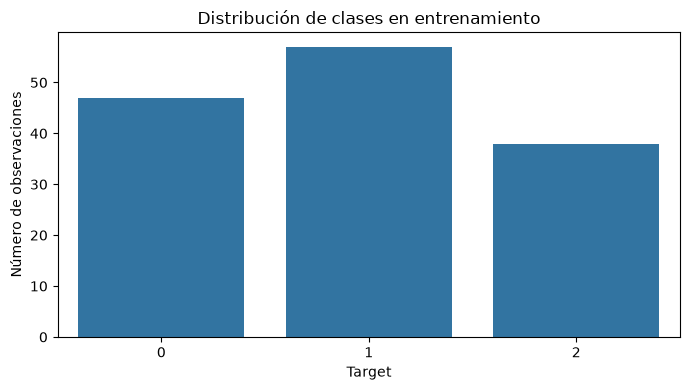

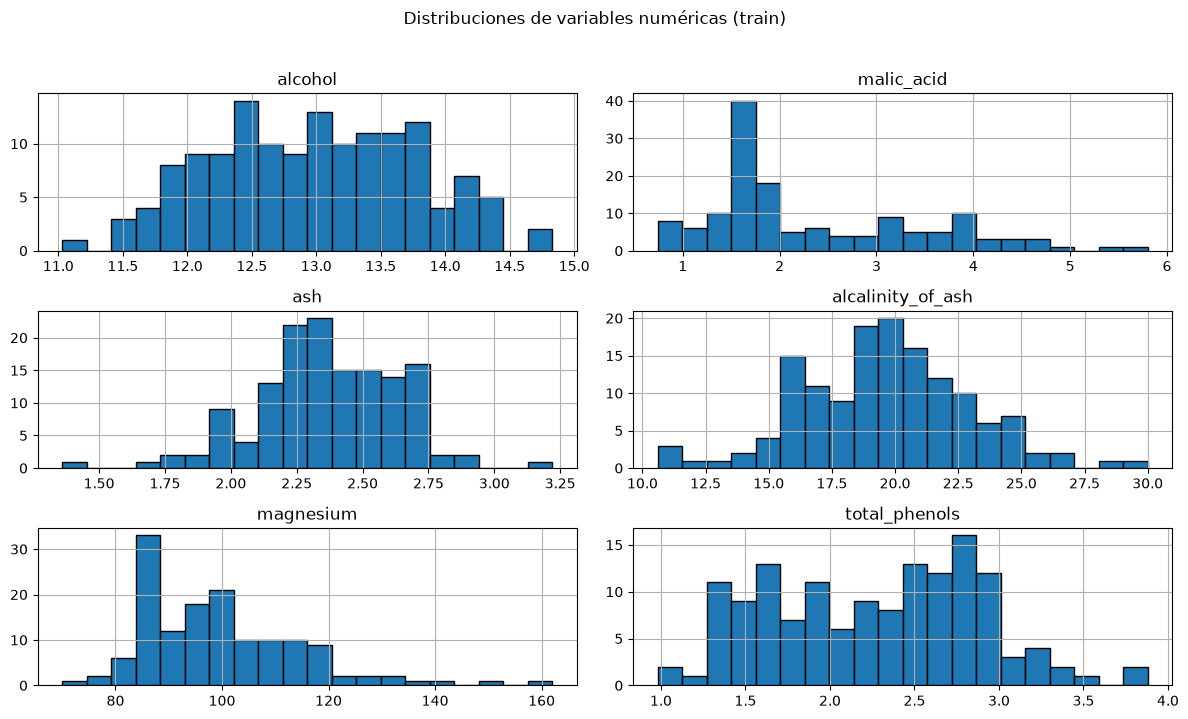

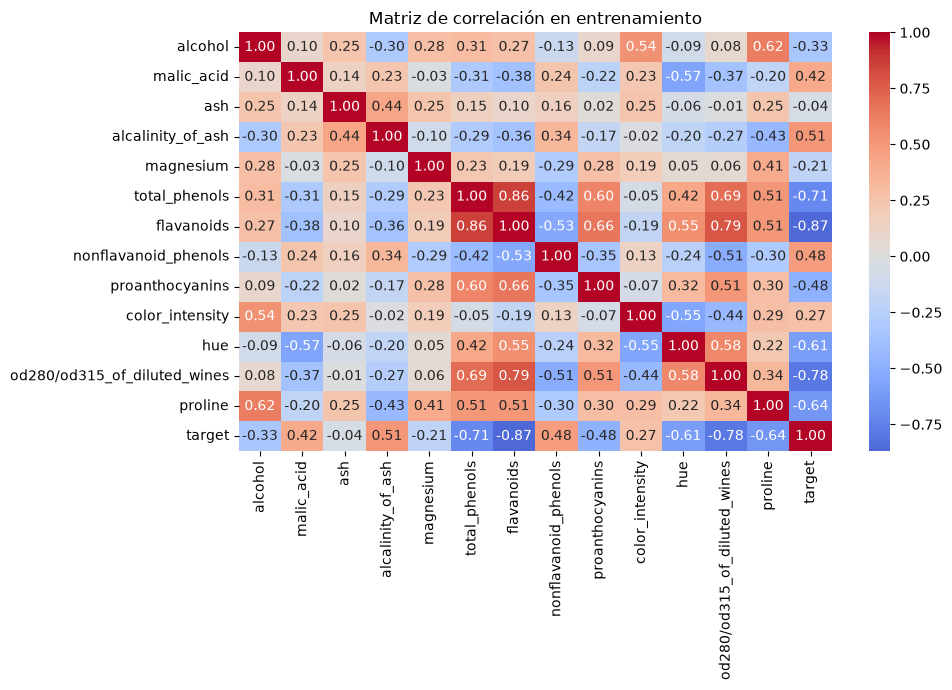

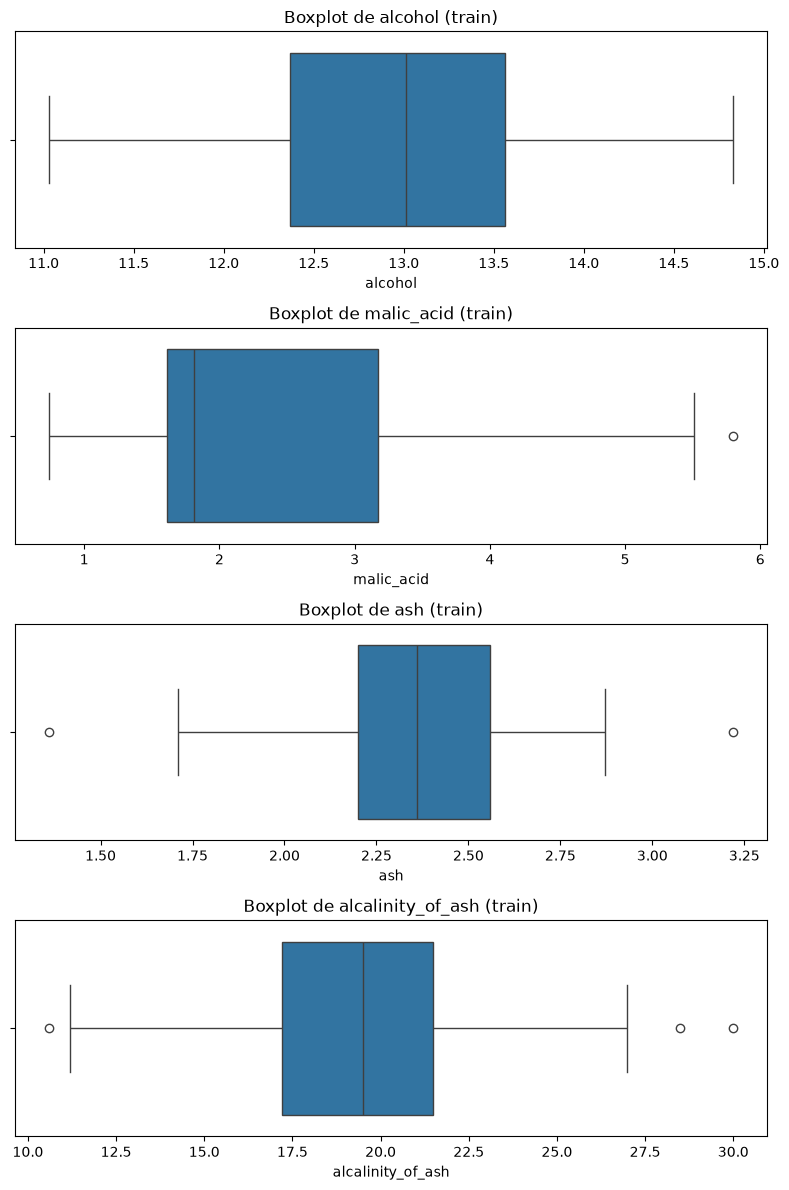

In [19]:
# EDA únicamente sobre train_df
numeric_cols = train_df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [col for col in numeric_cols if col != "target"]

if "target" not in train_df.columns:
    raise KeyError("No se encontró la columna 'target'.")

# 1. Distribución de clases
plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x="target")
plt.title("Distribución de clases en entrenamiento")
plt.xlabel("Target")
plt.ylabel("Número de observaciones")
plt.tight_layout()
plt.show()

# 2. Distribuciones de variables numéricas (hasta 6 variables)
cols_to_plot = feature_cols[:6]
if cols_to_plot:
    train_df[cols_to_plot].hist(bins=20, figsize=(12, 7), edgecolor="black")
    plt.suptitle("Distribuciones de variables numéricas (train)", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron variables numéricas para graficar.")

# 3. Correlaciones entre variables numéricas
if len(numeric_cols) >= 2:
    plt.figure(figsize=(10, 7))
    corr = train_df[numeric_cols].corr(numeric_only=True)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Matriz de correlación en entrenamiento")
    plt.tight_layout()
    plt.show()

# 4. Boxplots de variables numéricas (hasta 4 variables)
box_cols = feature_cols[:4]
if box_cols:
    fig, axes = plt.subplots(len(box_cols), 1, figsize=(8, 3 * len(box_cols)))
    if len(box_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, box_cols):
        sns.boxplot(data=train_df, x=col, ax=ax)
        ax.set_title(f"Boxplot de {col} (train)")
    plt.tight_layout()
    plt.show()


**Tres hallazgos del EDA (calculados exclusivamente sobre `train_df`):**

1. **Distribución de clases:** las clases están relativamente representadas en el entrenamiento: clase 0 tiene 47 filas (33,1 %), clase 1 tiene 57 (40,1 %) y clase 2 tiene 38 (26,8 %). La estratificación conserva proporciones similares a las del conjunto completo.
2. **Variables con diferencias entre clases:** el promedio de `flavanoids` es 2,93 para la clase 0, 2,01 para la clase 1 y 0,78 para la clase 2. `color_intensity` también presenta promedios distintos (5,48; 2,98; y 7,39, respectivamente). Estas variables podrían ser útiles para distinguir clases.
3. **Correlaciones entre predictores:** `total_phenols` y `flavanoids` muestran una correlación positiva alta (aprox. 0,86 en entrenamiento). `flavanoids` y `od280/od315_of_diluted_wines` también están correlacionadas (aprox. 0,79). Esta relación puede indicar información parcialmente redundante, por lo que conviene revisarla durante el modelado.

Los hallazgos son descriptivos; no implican causalidad. Los gráficos y estadísticas de esta sección usan únicamente `train_df`, no `test_df`.


## 4. Persistencia de datos y contrato

In [20]:
# Reiniciar índices y guardar los conjuntos sin incluir el índice como columna
train_to_save = train_df.reset_index(drop=True)
test_to_save = test_df.reset_index(drop=True)

train_path = PROCESSED_DATA_DIR / "train.csv"
test_path = PROCESSED_DATA_DIR / "test.csv"

train_to_save.to_csv(train_path, index=False)
test_to_save.to_csv(test_path, index=False)

# Contrato de datos para la siguiente etapa
TARGET = "target"
features = [col for col in df.columns if col != TARGET]

data_contract = {
    "target": TARGET,
    "features": features,
    "random_state": RANDOM_STATE,
    "test_size": 0.20
}

contract_path = ARTIFACTS_DIR / "data_contract.json"
with open(contract_path, "w", encoding="utf-8") as f:
    json.dump(data_contract, f, ensure_ascii=False, indent=2)

print("Archivos guardados:")
print(f"- {train_path}")
print(f"- {test_path}")
print(f"- {contract_path}")


Archivos guardados:
- c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\wine_data_challenge\data\processed\train.csv
- c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\wine_data_challenge\data\processed\test.csv
- c:\Users\lafon\OneDrive\Escritorio\Talleres IA\Semana 06\wine_data_challenge\artifacts\data_contract.json


In [21]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV y revisé su estructura.
- [x] Revisé valores nulos, duplicados y distribución de la clase.
- [x] Realicé un split estratificado y reproducible (80/20, `random_state=42`).
- [x] Reservé el conjunto de test y no lo utilicé para el EDA.
- [x] Guardé `train.csv`, `test.csv` y `data_contract.json`.
